# E1–E4 Spotify index benchmark analysis
**Fantastic-4-eign-Key · reproducible analysis notebook**

This notebook keeps the five-repetition baseline sessions separate from later experiment-specific reruns. **Do not call the newer E2/E3 sessions a fully fixed-code suite without verifying the Git commits and fixes.** E1 and E4 currently have no newer five-repetition runs. The report template requires fixed-code results for the main Results section.

**Data provenance:** `results/timings.csv` from the uploaded repository snapshot. The bundled CSV is copied alongside this notebook for standalone use. All times are converted from nanoseconds; query times are normalized by `n_ops`, and build time is presented in milliseconds for the complete index build.

In [36]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

# Locate the repository root whether running from
# the repository directory or the analysis directory.
cwd = Path.cwd()

if (cwd / "results" / "timings.csv").exists():
    ROOT = cwd
elif (cwd.parent / "results" / "timings.csv").exists():
    ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Cannot locate results/timings.csv. "
        "Run the notebook from the repository or analysis directory."
    )

DATA = ROOT / "results" / "timings.csv"
OUTPUT_DIR = ROOT / "analysis" / "figures"
SUMMARY_DIR = ROOT / "analysis" / "summaries"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    DATA,
    dtype={"session_id": "string", "code_version": "string"}
)

for c in ["n_keys", "n_ops", "rep", "total_ns", "memory_bytes"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df["ns_per_op"] = df["total_ns"] / df["n_ops"]
df["us_per_op"] = df["ns_per_op"] / 1000
df["build_ms"] = df["total_ns"] / 1e6

print("Loaded", len(df), "rows from", DATA)
print("Figures:", OUTPUT_DIR)
print("Summaries:", SUMMARY_DIR)

Loaded 5307 rows from /Users/evelynaltpeter/Files/Northeastern/2026/CS3300/Fantastic-4-eign-Key/results/timings.csv
Figures: /Users/evelynaltpeter/Files/Northeastern/2026/CS3300/Fantastic-4-eign-Key/analysis/figures
Summaries: /Users/evelynaltpeter/Files/Northeastern/2026/CS3300/Fantastic-4-eign-Key/analysis/summaries


In [37]:
# Find the correct session IDs

display(
    df[
        df["experiment"].isin([
            "E2_point_lookups",
            "E3_range_tempo"
        ])
    ]
    .groupby(
        ["experiment", "session_id", "code_version"],
        dropna=False
    )
    .agg(
        rows=("rep", "size"),
        reps=("rep", "nunique")
    )
    .reset_index()
    .sort_values(["experiment", "session_id"])
)

,experiment,session_id,code_version,rows,reps
0,E2_point_lookups,2c11c5c41b55,dd70faa,84,1
1,E2_point_lookups,c5bb2f35f32e,9ae426d,420,5
2,E2_point_lookups,cb982e14d36e,dd70faa,420,5
3,E3_range_tempo,1c6e2f7b7582,a0e890d,210,5
4,E3_range_tempo,36ffab8e8e14,dd70faa,210,5
5,E3_range_tempo,b1067c49dce9,dd70faa,42,1


## 1. Session manifest and data-quality checks
These session IDs explicitly exclude the one-repetition preliminary runs. E2/E3 newer runs are **candidate post-fix measurements**, not a substitute for verifying a single final code version across E1–E4.

In [38]:
SESSIONS = {
    'E1_build_memory': {'baseline': '64b25024b098'},
    'E2_point_lookups': {
        'baseline': 'cb982e14d36e',
        'later': 'c5bb2f35f32e'
    },
    'E3_range_tempo': {
        'baseline': '36ffab8e8e14',
        'later': '1c6e2f7b7582'
    },
    'E4_prefix_titles': {'baseline': '704c89457824'},
}

frames = []
for experiment, runs in SESSIONS.items():
    for phase, session in runs.items():
        part = df[(df.experiment == experiment) & (df.session_id == session)].copy()
        part['phase'] = phase
        frames.append(part)
selected = pd.concat(frames, ignore_index=True)
manifest = selected.groupby(['experiment','phase','session_id','code_version'], dropna=False).agg(
    rows=('rep','size'), reps=('rep','nunique'), indexes=('index_type','nunique'),
    missing_times=('total_ns',lambda s:s.isna().sum())
).reset_index()
display(manifest)
assert len(selected[selected.phase=='baseline']) == 1015
assert (selected.n_ops > 0).all()
assert selected.total_ns.notna().all()
assert not selected.duplicated(['session_id','experiment','index_type','operation','operation_param','n_keys','rep','index_param']).any()
print('Baseline: 1,015 rows; no missing timings, zero operation counts or duplicate configurations')

,experiment,phase,session_id,code_version,rows,reps,indexes,missing_times
0,E1_build_memory,baseline,64b25024b098,dd70faa,210,5,7,0
1,E2_point_lookups,baseline,cb982e14d36e,dd70faa,420,5,7,0
2,E2_point_lookups,later,c5bb2f35f32e,9ae426d,420,5,7,0
3,E3_range_tempo,baseline,36ffab8e8e14,dd70faa,210,5,7,0
4,E3_range_tempo,later,1c6e2f7b7582,a0e890d,210,5,7,0
5,E4_prefix_titles,baseline,704c89457824,dd70faa,175,5,7,0


Baseline: 1,015 rows; no missing timings, zero operation counts or duplicate configurations


## 2. Statistical summary
For each index/workload configuration, summarize five independent repetition measurements using the arithmetic mean, sample SD (`ddof=1`) and a two-sided 95% Student-t confidence interval (`t₀.₉₇₅,₄ ≈ 2.776`). These intervals describe variation across repetitions; they do not capture systematic differences between machines, code versions or workload generation. Build times use full-build milliseconds, query times use microseconds per operation.

In [39]:
group_cols = [
    "experiment", "phase", "code_version",
    "index_type", "operation", "operation_param", "n_keys"
]

selected["metric_value"] = np.where(
    selected.operation.eq("build"),
    selected.build_ms,
    selected.us_per_op
)

selected["metric_unit"] = np.where(
    selected.operation.eq("build"),
    "ms/build",
    "µs/query"
)

summary = (
    selected.groupby(
        group_cols + ["metric_unit"],
        dropna=False
    )["metric_value"]
    .agg(
        n="count",
        mean="mean",
        sd="std",
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

summary["iqr"] = summary["q3"] - summary["q1"]

summary["ci_halfwidth"] = (
    t.ppf(0.975, summary["n"] - 1)
    * summary["sd"]
    / np.sqrt(summary["n"])
)

summary["ci_low"] = summary["mean"] - summary["ci_halfwidth"]
summary["ci_high"] = summary["mean"] + summary["ci_halfwidth"]

display(summary.head(12).round(3))

summary.to_csv(
    SUMMARY_DIR / "e1_e4_statistical_summary.csv",
    index=False
)

,experiment,phase,code_version,index_type,operation,operation_param,n_keys,metric_unit,n,mean,sd,median,q1,q3,iqr,ci_halfwidth,ci_low,ci_high
0,E1_build_memory,baseline,dd70faa,avl_tree,build,NaN,1000,ms/build,5,4.494,0.174,4.400,4.366,4.665,0.299,0.216,4.278,4.711
1,E1_build_memory,baseline,dd70faa,avl_tree,build,NaN,3000,ms/build,5,16.393,0.125,16.374,16.346,16.410,0.064,0.155,16.239,16.548
2,E1_build_memory,baseline,dd70faa,avl_tree,build,NaN,10000,ms/build,5,78.468,14.613,71.386,67.526,92.788,25.262,18.144,60.324,96.612
3,E1_build_memory,baseline,dd70faa,avl_tree,build,NaN,30000,ms/build,5,232.232,5.059,235.302,227.352,235.458,8.106,6.282,225.951,238.514
4,E1_build_memory,baseline,dd70faa,avl_tree,build,NaN,60000,ms/build,5,498.304,6.768,494.733,493.540,505.604,12.064,8.404,489.901,506.708
5,E1_build_memory,baseline,dd70faa,avl_tree,build,NaN,114000,ms/build,5,1048.398,37.591,1025.017,1019.146,1088.258,69.112,46.676,1001.722,1095.074
6,E1_build_memory,baseline,dd70faa,bplus_tree,build,NaN,1000,ms/build,5,0.966,0.024,0.970,0.957,0.983,0.026,0.030,0.936,0.996
7,E1_build_memory,baseline,dd70faa,bplus_tree,build,NaN,3000,ms/build,5,3.346,0.193,3.295,3.186,3.490,0.304,0.239,3.107,3.586
8,E1_build_memory,baseline,dd70faa,bplus_tree,build,NaN,10000,ms/build,5,12.168,0.244,12.194,12.090,12.253,0.163,0.303,11.865,12.472
9,E1_build_memory,baseline,dd70faa,bplus_tree,build,NaN,30000,ms/build,5,41.534,0.752,41.248,41.008,42.233,1.224,0.934,40.600,42.467


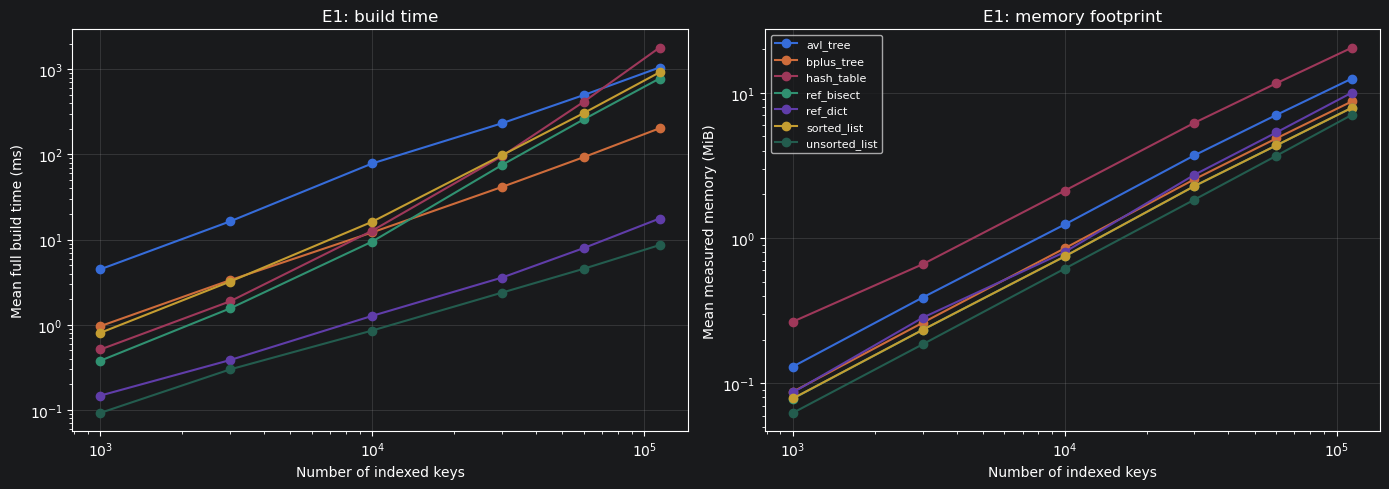

In [40]:
e1 = selected[(selected.experiment=='E1_build_memory') & (selected.phase=='baseline')]
fig, axes = plt.subplots(1,2,figsize=(14,5))
for index, g in e1.groupby('index_type'):
    a = g.groupby('n_keys',as_index=False).agg(build_ms=('build_ms','mean'),memory_bytes=('memory_bytes','mean'))
    axes[0].plot(a.n_keys, a.build_ms, marker='o',label=index)
    axes[1].plot(a.n_keys, a.memory_bytes/2**20, marker='o',label=index)
axes[0].set(xlabel='Number of indexed keys',ylabel='Mean full build time (ms)',title='E1: build time')
axes[1].set(xlabel='Number of indexed keys',ylabel='Mean measured memory (MiB)',title='E1: memory footprint')
for ax in axes: ax.grid(alpha=.25); ax.set_xscale('log'); ax.set_yscale('log')
axes[1].legend(loc='best',fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / f'E1_build_memory.png',dpi=180); plt.show()

## 3. E1 — Build time and memory versus dataset size
Memory is reported in MiB. E1 records memory once per build and has five repetitions per index/size. Charts use the **baseline** session because there is no complete newer E1 run in the snapshot.

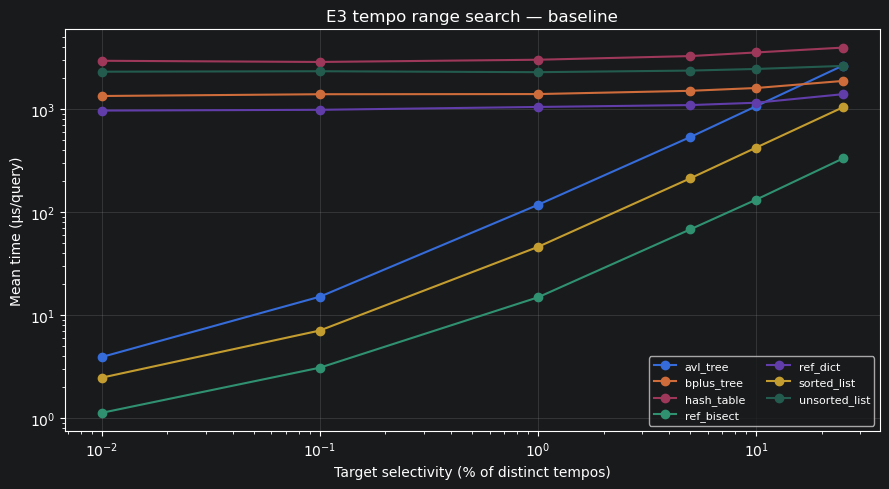

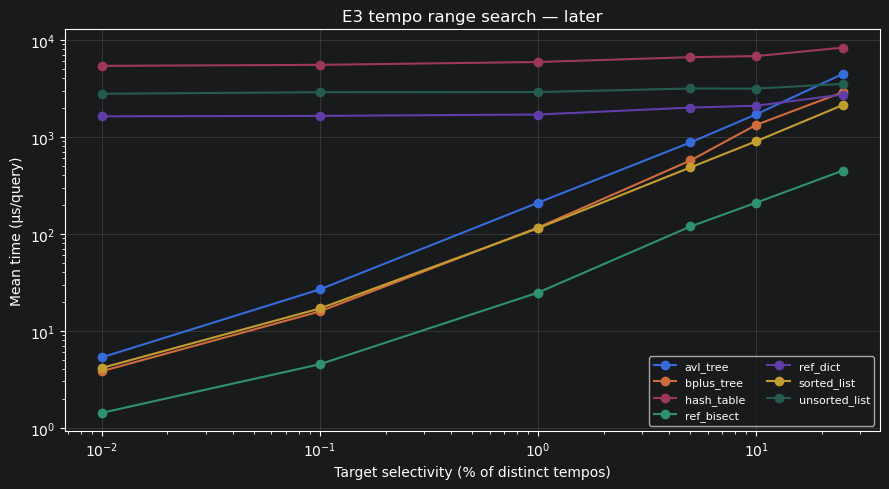

In [41]:
e3=summary[summary.experiment=='E3_range_tempo'].copy()
e3['target_percent']=pd.to_numeric(e3.operation_param)*100
for phase in ['baseline','later']:
    fig,ax=plt.subplots(figsize=(9,5))
    for index,g in e3[e3.phase==phase].groupby('index_type'):
        g=g.sort_values('target_percent')
        ax.plot(g.target_percent,g['mean'],marker='o',label=index)
    ax.set(xlabel='Target selectivity (% of distinct tempos)',ylabel='Mean time (µs/query)',title=f'E3 tempo range search — {phase}')
    ax.set_xscale('log');ax.set_yscale('log');ax.grid(alpha=.25);ax.legend(fontsize=8,ncol=2)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR / f'E3_range_{phase}.png',dpi=180);plt.show()

## 4. E2 — Point hits and misses versus dataset size
Compare baseline and later sessions **separately**. A faster index on one size is not automatically the best for every size. A log y-axis helps expose large performance differences.

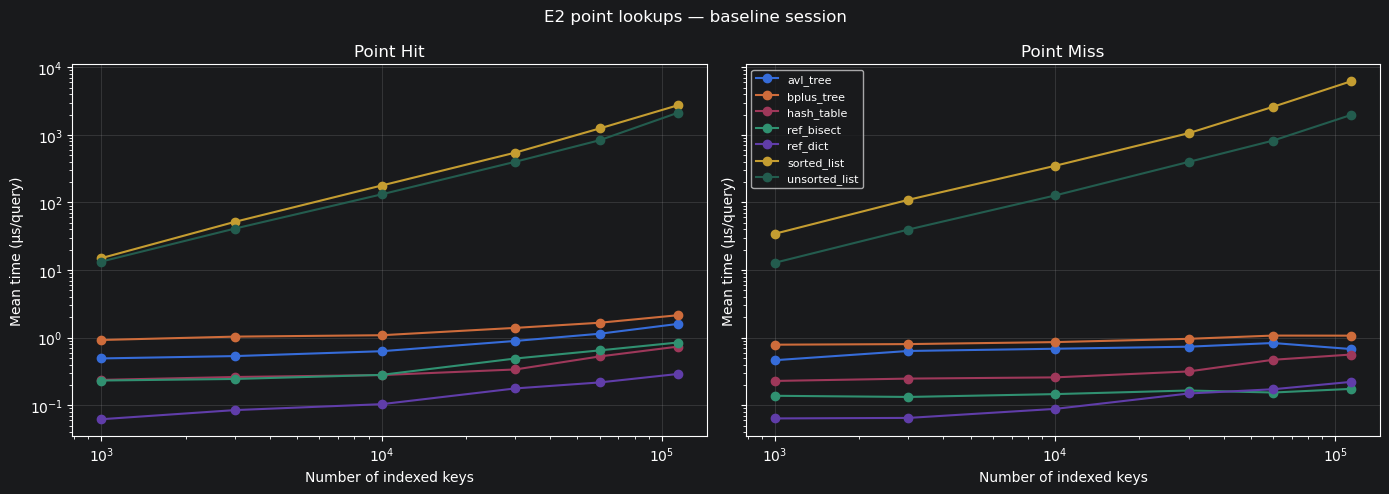

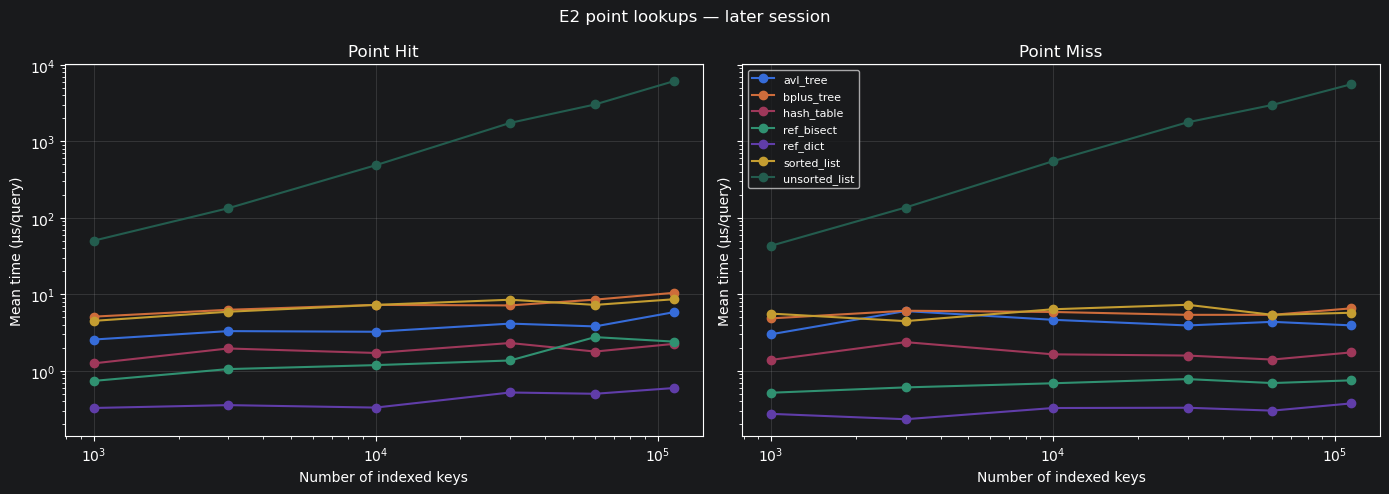

In [42]:
e2 = summary[summary.experiment=='E2_point_lookups']
for phase in ['baseline','later']:
    fig,axes=plt.subplots(1,2,figsize=(14,5),sharey=True)
    for ax,op in zip(axes,['point_hit','point_miss']):
        d=e2[(e2.phase==phase)&(e2.operation==op)]
        for index,g in d.groupby('index_type'):
            g=g.sort_values('n_keys')
            ax.plot(g.n_keys,g['mean'],marker='o',label=index)
        ax.set(title=op.replace('_',' ').title(),xlabel='Number of indexed keys',ylabel='Mean time (µs/query)')
        ax.set_xscale('log');ax.set_yscale('log');ax.grid(alpha=.25)
    axes[1].legend(fontsize=8)
    fig.suptitle(f'E2 point lookups — {phase} session')
    fig.tight_layout();fig.savefig(OUTPUT_DIR / f'E2_point_{phase}.png',dpi=180);plt.show()

In [43]:
#E3/E4 Validation

for experiment in ["E3_range_tempo", "E4_prefix_titles"]:
    subset = selected[selected["experiment"] == experiment]

    sizes = sorted(subset["n_keys"].dropna().unique())
    reps = sorted(subset["rep"].dropna().unique())

    print(f"{experiment}:")
    print("  Dataset sizes:", sizes)
    print("  Repetitions:", reps)

    assert len(sizes) == 1, (
        f"{experiment} contains multiple dataset sizes."
    )

    assert len(reps) == 5, (
        f"{experiment} does not contain five repetitions."
    )

E3_range_tempo:
  Dataset sizes: [np.int64(114000)]
  Repetitions: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
E4_prefix_titles:
  Dataset sizes: [np.int64(113999)]
  Repetitions: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## 5. E3 — Tempo range queries versus selectivity
The generator targets a percentage of **distinct tempo values**, not necessarily Spotify records. Prior validation on the source dataset found mean record-level selectivities of 0.0107%, 0.0980%, 1.0001%, 5.1632%, 10.4134% and 26.9740%. State this limitation in the report. Each query returns a range of matching records, so output size contributes to runtime.

## 6. E4 — Track-title prefix searches
Prefixes of length 1–5 are sampled from existing titles, so every generated prefix matches at least one key. Query times can reflect different output cardinalities; avoid interpreting length as the only driver of latency.

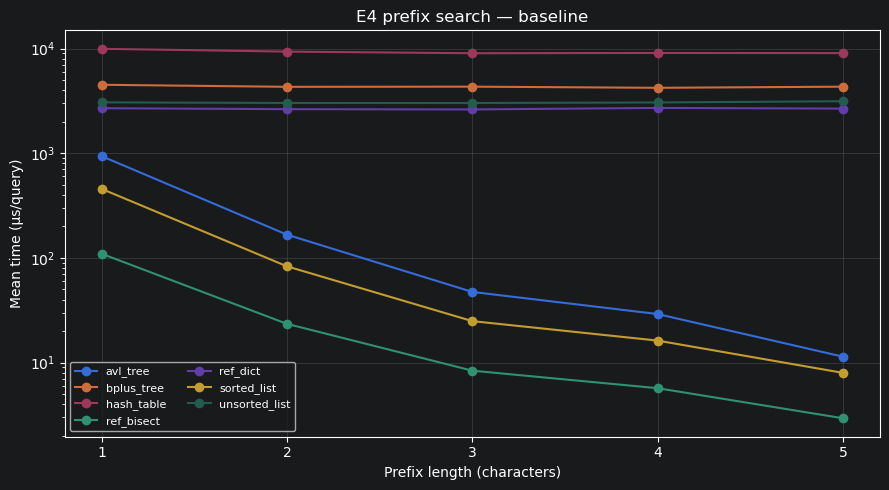

In [44]:
e4=summary[(summary.experiment=='E4_prefix_titles') & (summary.phase=='baseline')].copy()
e4['prefix_length']=pd.to_numeric(e4.operation_param)
fig,ax=plt.subplots(figsize=(9,5))
for index,g in e4.groupby('index_type'):
    g=g.sort_values('prefix_length')
    ax.plot(g.prefix_length,g['mean'],marker='o',label=index)
ax.set(xlabel='Prefix length (characters)',ylabel='Mean time (µs/query)',title='E4 prefix search — baseline')
ax.set_xticks([1,2,3,4,5]);ax.set_yscale('log');ax.grid(alpha=.25);ax.legend(fontsize=8,ncol=2)
fig.tight_layout();fig.savefig(OUTPUT_DIR / f'E4_prefix_baseline.png',dpi=180);plt.show()

## 7. Compare E2/E3 before versus later versions
These are **not controlled before/after causal estimates** until code changes and workload equivalence are verified. The tables below are useful for triage and can flag unexpected regressions.

In [45]:
compare_keys=['experiment','index_type','operation','operation_param','n_keys']
comp=summary[summary.experiment.isin(['E2_point_lookups','E3_range_tempo'])].pivot_table(
    index=compare_keys,columns='phase',values='mean',aggfunc='first'
).dropna().reset_index()
comp['baseline_to_later_speedup']=comp['baseline']/comp['later']
display(comp.sort_values('baseline_to_later_speedup',ascending=False).head(15).round(3))
display(comp.sort_values('baseline_to_later_speedup').head(15).round(3))
comp.to_csv(
    SUMMARY_DIR / 'e2_e3_version_comparison.csv',
    index=False
)

phase,experiment,index_type,operation,operation_param,n_keys,baseline,later,baseline_to_later_speedup
71,E2_point_lookups,sorted_list,point_miss,0.000,114000,6213.710,5.746,1081.355
70,E2_point_lookups,sorted_list,point_miss,0.000,60000,2600.759,5.401,481.510
90,E3_range_tempo,bplus_tree,range,0.000,114000,1344.091,3.825,351.352
65,E2_point_lookups,sorted_list,point_hit,1.000,114000,2735.833,8.625,317.187
64,E2_point_lookups,sorted_list,point_hit,1.000,60000,1243.088,7.282,170.717
69,E2_point_lookups,sorted_list,point_miss,0.000,30000,1059.493,7.306,145.026
91,E3_range_tempo,bplus_tree,range,0.001,114000,1398.330,15.821,88.383
63,E2_point_lookups,sorted_list,point_hit,1.000,30000,545.904,8.507,64.170
68,E2_point_lookups,sorted_list,point_miss,0.000,10000,348.152,6.386,54.519
67,E2_point_lookups,sorted_list,point_miss,0.000,3000,109.524,4.469,24.509


phase,experiment,index_type,operation,operation_param,n_keys,baseline,later,baseline_to_later_speedup
31,E2_point_lookups,hash_table,point_miss,0.0,3000,0.248,2.374,0.104
7,E2_point_lookups,avl_tree,point_miss,0.0,3000,0.635,6.050,0.105
19,E2_point_lookups,bplus_tree,point_miss,0.0,3000,0.802,6.109,0.131
25,E2_point_lookups,hash_table,point_hit,1.0,3000,0.262,1.961,0.133
20,E2_point_lookups,bplus_tree,point_miss,0.0,10000,0.858,5.884,0.146
27,E2_point_lookups,hash_table,point_hit,1.0,30000,0.338,2.312,0.146
8,E2_point_lookups,avl_tree,point_miss,0.0,10000,0.685,4.648,0.147
14,E2_point_lookups,bplus_tree,point_hit,1.0,10000,1.085,7.281,0.149
6,E2_point_lookups,avl_tree,point_miss,0.0,1000,0.463,3.008,0.154
32,E2_point_lookups,hash_table,point_miss,0.0,10000,0.258,1.645,0.157


## 8. F1–F4 recommendation evidence (complete after final code version is agreed)
Use this table to identify promising options, then check whether the index supports the required operation, its memory/build costs, and whether differences are stable across configurations. **Do not simply pick the global fastest median across different workloads.**

- **F1 Track page:** E2 point hits and misses, especially larger datasets; consider hash/reference indexes and build/memory trade-offs
- **F2 Search-as-you-type:** E4 prefix searches; check prefix support and output size
- **F3 Workout mode:** E3 tempo ranges; check selectivity and returned-track counts
- **F4 Catalog import:** E1 build time and memory, plus any insertion-order effects from E5 once available

The final report should include the recommended custom index, a runner-up, supporting measurements, trade-offs, and what could change the choice. Reference implementations are benchmarks, not automatically the recommended custom implementation.

In [46]:
for exp,phase in [('E1_build_memory','baseline'),('E2_point_lookups','later'),('E3_range_tempo','later'),('E4_prefix_titles','baseline')]:
    s=summary[(summary.experiment==exp)&(summary.phase==phase)]
    print(f'\n{exp} ({phase}):')
    if exp=='E2_point_lookups': s=s[s.n_keys==s.n_keys.max()]
    elif exp=='E1_build_memory': s=s[s.n_keys==s.n_keys.max()]
    elif exp=='E3_range_tempo': s=s[s.operation_param=='0.01']
    elif exp=='E4_prefix_titles': s=s[s.operation_param=='3']
    display(s[['index_type','operation','operation_param','n_keys','mean','ci_low','ci_high','metric_unit']].sort_values('mean').round(3))


E1_build_memory (baseline):


,index_type,operation,operation_param,n_keys,mean,ci_low,ci_high,metric_unit
41,unsorted_list,build,NaN,114000,8.632,8.312,8.953,ms/build
29,ref_dict,build,NaN,114000,17.688,16.818,18.559,ms/build
11,bplus_tree,build,NaN,114000,202.768,199.632,205.905,ms/build
23,ref_bisect,build,NaN,114000,778.697,754.669,802.726,ms/build
35,sorted_list,build,NaN,114000,919.756,872.475,967.037,ms/build
5,avl_tree,build,NaN,114000,1048.398,1001.722,1095.074,ms/build
17,hash_table,build,NaN,114000,1796.121,1787.771,1804.471,ms/build



E2_point_lookups (later):


,index_type,operation,operation_param,n_keys,mean,ci_low,ci_high,metric_unit
185,ref_dict,point_miss,0.0,114000,0.375,0.309,0.441,µs/query
179,ref_dict,point_hit,1.0,114000,0.596,0.550,0.641,µs/query
173,ref_bisect,point_miss,0.0,114000,0.751,0.394,1.109,µs/query
161,hash_table,point_miss,0.0,114000,1.741,1.546,1.936,µs/query
155,hash_table,point_hit,1.0,114000,2.251,1.924,2.577,µs/query
167,ref_bisect,point_hit,1.0,114000,2.413,2.105,2.721,µs/query
137,avl_tree,point_miss,0.0,114000,3.933,3.527,4.339,µs/query
197,sorted_list,point_miss,0.0,114000,5.746,4.883,6.609,µs/query
131,avl_tree,point_hit,1.0,114000,5.839,4.876,6.802,µs/query
149,bplus_tree,point_miss,0.0,114000,6.560,5.587,7.532,µs/query



E3_range_tempo (later):


,index_type,operation,operation_param,n_keys,mean,ci_low,ci_high,metric_unit



E4_prefix_titles (baseline):


,index_type,operation,operation_param,n_keys,mean,ci_low,ci_high,metric_unit


## 9. Outstanding validation and rerun checklist
1. Confirm the exact commits and fixes represented by E2 `9ae426d` and E3 `a0e890d`; they are not the same code version
2. Decide on a single **fully fixed** code commit and rerun E1–E4 at five repetitions if any of the indexes used in the experiments changed; use new session IDs, retain the baseline
3. Verify correctness tests and generator behavior on the fixed commit
4. For cross-machine Part E, ensure all CORE rows being compared use the same baseline commit and the same fixed commit
5. Update this notebook's `SESSIONS` mapping with the final runs and regenerate the figures
6. Cite notebook section/figure names in the PDF report; discuss 95% CI, crossover points, theory, and limitations